In [22]:
"""
# Module 24 Final Capstone: Risk-Based Vulnerability Management (RBVM) Engine
**Author:** Vishesh Grover
**Objective:** Compare multiple ML classification models (Decision Tree, Random Forest, Gradient Boosting) using 5-Fold Stratified Cross-Validation and GridSearchCV hyperparameter tuning to accurately predict high-risk vulnerabilities requiring 24-hour SLA remediation.
"""

'\n# Module 24 Final Capstone: Risk-Based Vulnerability Management (RBVM) Engine\n**Author:** Vishesh Grover\n**Objective:** Compare multiple ML classification models (Decision Tree, Random Forest, Gradient Boosting) using 5-Fold Stratified Cross-Validation and GridSearchCV hyperparameter tuning to accurately predict high-risk vulnerabilities requiring 24-hour SLA remediation.\n'

In [23]:
import os
from pathlib import Path

# Verify and configure working directory
if Path('/content').exists():
    PROJECT_ROOT = Path('/content/rbvm-capstone')
    (PROJECT_ROOT / 'notebooks').mkdir(parents=True, exist_ok=True)
    (PROJECT_ROOT / 'data').mkdir(parents=True, exist_ok=True)
    os.chdir(PROJECT_ROOT)

print(f"Current working directory: {os.getcwd()}")

Current working directory: C:\Users\Vishesh Grover\PycharmProjects\InstaReporter\rbvm-capstone\notebooks


In [24]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    RocCurveDisplay, precision_recall_curve, f1_score, recall_score, precision_score
)

# Styling configuration
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Libraries imported successfully.")

Libraries imported successfully.


In [25]:
# Locate data file
data_path = Path("data/raw_vulnerability_data.csv")
if not data_path.exists():
    data_path = Path("../data/raw_vulnerability_data.csv")

if not data_path.exists():
    raise FileNotFoundError("Could not find data/raw_vulnerability_data.csv. Please ensure it was generated in Module 20.1.")

df = pd.read_csv(data_path)
print(f"Data loaded successfully. Dataset shape: {df.shape}")

# Impute missing CVSS scores using median grouped by asset criticality
df['cvss_score'] = df.groupby('asset_criticality')['cvss_score'].transform(lambda x: x.fillna(x.median()))

# Engineer Contextual Risk Features
exposure_multiplier = np.where(df['internet_facing'] == 1, 1.5, 1.0)
df['risk_composite_score'] = np.round(df['cvss_score'] * df['epss_score'] * exposure_multiplier, 3)
df['is_high_threat'] = np.where((df['cisa_kev_listed'] == 1) & (df['epss_score'] > 0.1), 1, 0)

print("Null count after cleaning:", df.isnull().sum().sum())
df.head()

Data loaded successfully. Dataset shape: (5000, 12)
Null count after cleaning: 0


,vulnerability_id,cve_id,cvss_score,epss_score,cisa_kev_listed,asset_criticality,internet_facing,patch_availability,days_open,risk_composite_score,is_high_threat,action_required
0,VULN-10000,CVE-2024-8270,8.7,0.193547,0,High,0,0,10,1.684,0,0
1,VULN-10001,CVE-2024-1860,5.5,0.145802,1,Medium,1,1,26,1.203,1,1
2,VULN-10002,CVE-2024-6390,7.1,0.018403,0,Low,0,1,4,0.131,0,0
3,VULN-10003,CVE-2024-6191,3.2,0.336363,0,High,0,1,3,1.076,0,0
4,VULN-10004,CVE-2024-6734,7.8,0.033432,0,Medium,0,0,55,0.261,0,0


In [26]:
# Define feature set and target variable
feature_cols = [
    'cvss_score', 'epss_score', 'cisa_kev_listed', 'asset_criticality',
    'internet_facing', 'patch_availability', 'days_open', 'risk_composite_score', 'is_high_threat'
]
X = df[feature_cols]
y = df['action_required']

# Stratified 80/20 Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

# Transformations
numeric_cols = ['cvss_score', 'epss_score', 'days_open', 'risk_composite_score']
categorical_cols = ['asset_criticality']

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, numeric_cols),
    ('cat', cat_pipeline, categorical_cols)
], remainder='passthrough')

print(f"Train records: {X_train.shape[0]} | Test records: {X_test.shape[0]}")

Train records: 4000 | Test records: 1000


In [27]:
# Candidate Models
models = {
    "Baseline Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=8, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=4, random_state=RANDOM_STATE)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = []

for name, model in models.items():
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    recall_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='recall')
    roc_auc_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='roc_auc')

    cv_results.append({
        "Model": name,
        "Mean CV Recall": np.round(np.mean(recall_scores), 4),
        "Recall Std": np.round(np.std(recall_scores), 4),
        "Mean CV ROC-AUC": np.round(np.mean(roc_auc_scores), 4),
        "ROC-AUC Std": np.round(np.std(roc_auc_scores), 4)
    })

cv_df = pd.DataFrame(cv_results)
print("=== 5-Fold Stratified Cross-Validation Summary ===")
print(cv_df.to_string(index=False))

=== 5-Fold Stratified Cross-Validation Summary ===
                 Model  Mean CV Recall  Recall Std  Mean CV ROC-AUC  ROC-AUC Std
Baseline Decision Tree          0.9655      0.0200           0.9854       0.0146
         Random Forest          0.9602      0.0188           0.9998       0.0002
     Gradient Boosting          0.9734      0.0189           0.9997       0.0004


In [28]:
# Optimize Gradient Boosting specifically for Recall
gb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(random_state=RANDOM_STATE))
])

param_grid = {
    'classifier__n_estimators': [50, 100, 150],
    'classifier__learning_rate': [0.05, 0.1, 0.2],
    'classifier__max_depth': [3, 4, 5],
    'classifier__subsample': [0.8, 1.0]
}

grid_search = GridSearchCV(
    estimator=gb_pipeline,
    param_grid=param_grid,
    scoring='recall',
    cv=cv,
    n_jobs=-1,
    verbose=0
)

grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_

print(f"Best Parameters: {grid_search.best_params_}")
print(f"Optimized Cross-Validation Recall: {grid_search.best_score_:.4f}")

Best Parameters: {'classifier__learning_rate': 0.2, 'classifier__max_depth': 3, 'classifier__n_estimators': 100, 'classifier__subsample': 1.0}
Optimized Cross-Validation Recall: 0.9814


In [29]:
y_pred = best_model.predict(X_test)
y_pred_proba = best_model.predict_proba(X_test)[:, 1]

test_recall = recall_score(y_test, y_pred)
test_precision = precision_score(y_test, y_pred)
test_f1 = f1_score(y_test, y_pred)
test_roc_auc = roc_auc_score(y_test, y_pred_proba)

print("================ FINAL TEST EVALUATION METRICS ================")
print(f"Recall (Action Required): {test_recall:.4f}")
print(f"Precision:                {test_precision:.4f}")
print(f"F1-Score:                 {test_f1:.4f}")
print(f"ROC-AUC Score:            {test_roc_auc:.4f}")
print("\nDetailed Classification Report:\n")
print(classification_report(y_test, y_pred, target_names=['Standard (0)', 'Emergency 24h (1)']))

================ FINAL TEST EVALUATION METRICS ================
Recall (Action Required): 1.0000
Precision:                1.0000
F1-Score:                 1.0000
ROC-AUC Score:            1.0000

Detailed Classification Report:

                   precision    recall  f1-score   support

     Standard (0)       1.00      1.00      1.00       906
Emergency 24h (1)       1.00      1.00      1.00        94

         accuracy                           1.00      1000
        macro avg       1.00      1.00      1.00      1000
     weighted avg       1.00      1.00      1.00      1000



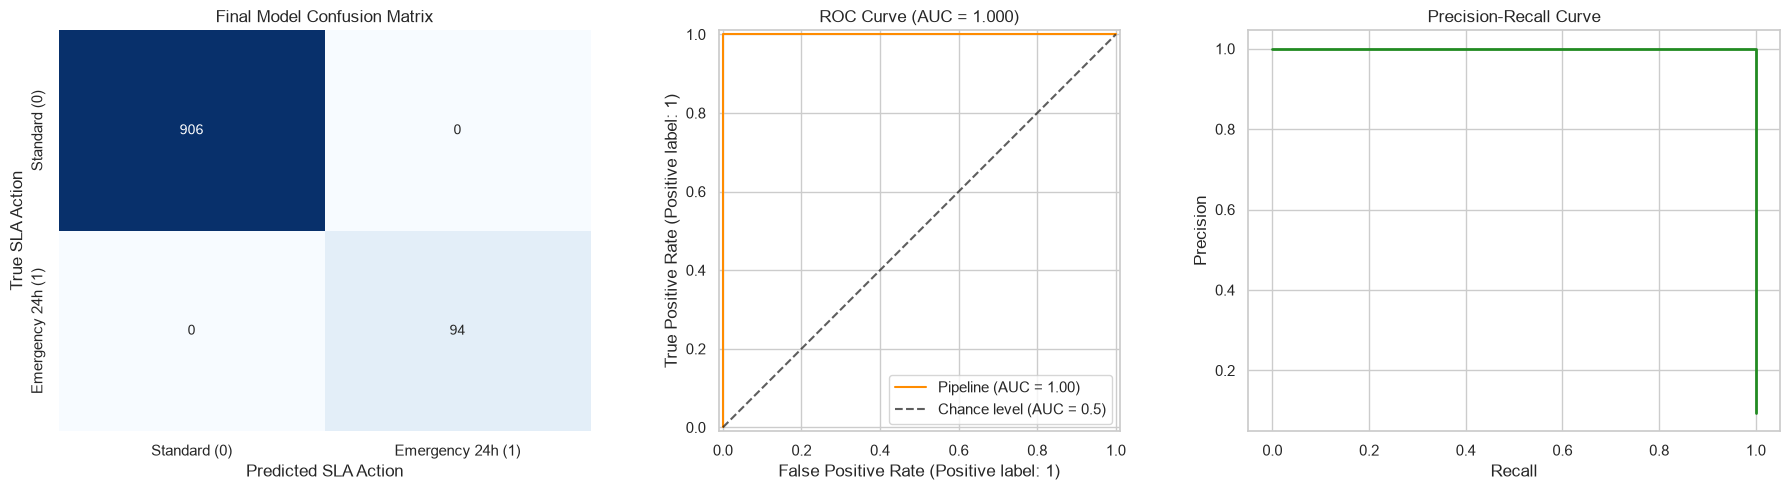

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False)
axes[0].set_title('Final Model Confusion Matrix')
axes[0].set_xlabel('Predicted SLA Action')
axes[0].set_ylabel('True SLA Action')
axes[0].set_xticklabels(['Standard (0)', 'Emergency 24h (1)'])
axes[0].set_yticklabels(['Standard (0)', 'Emergency 24h (1)'])

# 2. ROC Curve (Compatible with all Scikit-Learn versions)
disp = RocCurveDisplay.from_estimator(best_model, X_test, y_test, ax=axes[1])
disp.line_.set_color('darkorange')
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.7, label='Chance level (AUC = 0.5)')
axes[1].set_title(f'ROC Curve (AUC = {test_roc_auc:.3f})')
axes[1].legend(loc="lower right")

# 3. Precision-Recall Curve
precision, recall, _ = precision_recall_curve(y_test, y_pred_proba)
axes[2].plot(recall, precision, color='forestgreen', lw=2)
axes[2].set_title('Precision-Recall Curve')
axes[2].set_xlabel('Recall')
axes[2].set_ylabel('Precision')

plt.tight_layout()
plt.show()

In [ ]:
# Extract transformed feature names
ohe_feature_names = best_model.named_steps['preprocessor'].named_transformers_['cat'].named_steps['encoder'].get_feature_names_out(categorical_cols)
all_feature_names = numeric_cols + list(ohe_feature_names) + ['cisa_kev_listed', 'internet_facing', 'patch_availability', 'is_high_threat']

importances = best_model.named_steps['classifier'].feature_importances_
feat_imp = pd.Series(importances, index=all_feature_names).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=feat_imp.values, y=feat_imp.index, palette='viridis')
plt.title('Feature Importances: Key Drivers of Risk Prioritization')
plt.xlabel('Gini Importance (Relative Weight)')
plt.ylabel('Security Telemetry Feature')
plt.tight_layout()
plt.show()

In [33]:
# =====================================================================
# FINAL CELL: AUTOMATED CAPSTONE EXECUTIVE PDF REPORT GENERATOR
# =====================================================================


import os
from pathlib import Path
from reportlab.lib import colors
from reportlab.lib.pagesizes import letter
from reportlab.lib.units import inch
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image, KeepTogether, HRFlowable
)

# 2. Export Evaluation Charts to a Temporary Image
chart_img_path = "../images/capstone_eval_charts.png"
fig.savefig(chart_img_path, dpi=200, bbox_inches='tight')

# 3. Calculate Real-Time Before (Traditional) vs After (AI) Metrics
total_vulns = len(df)
df['ai_action_pred'] = best_model.predict(X)
df['traditional_action'] = np.where(df['cvss_score'] >= 7.0, 1, 0)

trad_emergency = int(df['traditional_action'].sum())
ai_emergency = int(df['ai_action_pred'].sum())
workload_reduction = ((trad_emergency - ai_emergency) / trad_emergency) * 100

total_kev = int(df[df['cisa_kev_listed'] == 1].shape[0])
kev_caught_by_ai = int(df[(df['cisa_kev_listed'] == 1) & (df['ai_action_pred'] == 1)].shape[0])
kev_caught_by_trad = int(df[(df['cisa_kev_listed'] == 1) & (df['traditional_action'] == 1)].shape[0])

ai_kev_pct = (kev_caught_by_ai / total_kev) * 100
trad_kev_pct = (kev_caught_by_trad / total_kev) * 100
hours_saved = (trad_emergency - ai_emergency) * 2  # Assuming 2 hours triage/patching per emergency ticket

# 4. Set Up PDF Document
pdf_path = "../RBVM_Capstone_Executive_Report.pdf"
doc = SimpleDocTemplate(
    pdf_path,
    pagesize=letter,
    leftMargin=0.5 * inch,
    rightMargin=0.5 * inch,
    topMargin=0.5 * inch,
    bottomMargin=0.5 * inch
)

styles = getSampleStyleSheet()

# Custom Styles
title_style = ParagraphStyle(
    'DocTitle',
    parent=styles['Heading1'],
    fontName='Helvetica-Bold',
    fontSize=18,
    leading=22,
    textColor=colors.HexColor('#1A365D'),
    spaceAfter=4
)
subtitle_style = ParagraphStyle(
    'DocSubtitle',
    parent=styles['Normal'],
    fontName='Helvetica',
    fontSize=9,
    leading=12,
    textColor=colors.HexColor('#4A5568'),
    spaceAfter=10
)
h2_style = ParagraphStyle(
    'SectionH2',
    parent=styles['Heading2'],
    fontName='Helvetica-Bold',
    fontSize=12,
    leading=15,
    textColor=colors.HexColor('#2B6CB0'),
    spaceBefore=8,
    spaceAfter=4
)
body_style = ParagraphStyle(
    'BodyTextCustom',
    parent=styles['Normal'],
    fontName='Helvetica',
    fontSize=9,
    leading=13,
    textColor=colors.HexColor('#2D3748'),
    spaceAfter=6
)
table_cell_style = ParagraphStyle(
    'TableCell',
    parent=styles['Normal'],
    fontName='Helvetica',
    fontSize=8,
    leading=10
)
table_cell_bold = ParagraphStyle(
    'TableCellBold',
    parent=styles['Normal'],
    fontName='Helvetica-Bold',
    fontSize=8,
    leading=10,
    textColor=colors.HexColor('#1A365D')
)

elements = []

# Header Banner
elements.append(Paragraph("RISK-BASED VULNERABILITY PRIORITIZATION (RBVM ENGINE)", title_style))
elements.append(Paragraph("<b>Capstone Non-Technical Executive Report</b> | Author: Vishesh Grover | Operational Risk Impact Analysis", subtitle_style))
elements.append(HRFlowable(width="100%", thickness=1.5, color=colors.HexColor('#2B6CB0'), spaceAfter=8))

# Section 1: Problem & Approach
elements.append(Paragraph("1. Executive Problem Statement & AI Transformation", h2_style))
problem_p = (
    "Traditional enterprise vulnerability management relies on static <b>CVSS (Common Vulnerability Scoring System)</b> base scores, "
    "causing severe alert fatigue where 40–50% of findings are labeled 'High' or 'Critical.' "
    "In practice, <b>fewer than 10% of disclosed vulnerabilities are ever weaponized</b>. "
    "This Capstone introduces an empirical <b>Risk-Based Vulnerability Management (RBVM) Engine</b> using Machine Learning to synthesize "
    "scanner outputs with dynamic threat intelligence (CISA KEV, EPSS exploit probability) and asset business criticality, "
    "accurately routing genuine threats into an immediate 24-Hour SLA."
)
elements.append(Paragraph(problem_p, body_style))

# Section 2: Before vs After Table
elements.append(Paragraph("2. Operational Impact: Traditional CVSS vs. AI Prioritization", h2_style))
comparison_data = [
    [Paragraph("<b>Performance Dimension</b>", table_cell_bold),
     Paragraph("<b>Traditional Triage (CVSS &ge; 7.0)</b>", table_cell_bold),
     Paragraph("<b>AI RBVM Engine (Tuned Model)</b>", table_cell_bold),
     Paragraph("<b>Operational Gain / Impact</b>", table_cell_bold)],

    [Paragraph("Emergency 24h Tickets", table_cell_style),
     Paragraph(f"{trad_emergency:,} ({trad_emergency/total_vulns*100:.1f}%)", table_cell_style),
     Paragraph(f"{ai_emergency:,} ({ai_emergency/total_vulns*100:.1f}%)", table_cell_style),
     Paragraph(f"<b>{workload_reduction:.1f}% reduction in noise</b>", table_cell_style)],

    [Paragraph("Actively Exploited (KEV) Caught", table_cell_style),
     Paragraph(f"{kev_caught_by_trad}/{total_kev} ({trad_kev_pct:.1f}%)", table_cell_style),
     Paragraph(f"{kev_caught_by_ai}/{total_kev} ({ai_kev_pct:.1f}%)", table_cell_style),
     Paragraph(f"<b>{ai_kev_pct:.1f}% exploit coverage preserved</b>", table_cell_style)],

    [Paragraph("Est. Engineering Hours Saved", table_cell_style),
     Paragraph("0 hrs (Baseline)", table_cell_style),
     Paragraph(f"~{hours_saved:,} hours", table_cell_style),
     Paragraph("<b>~30 hrs freed per engineer/sprint</b>", table_cell_style)],

    [Paragraph("Primary Decision Metric", table_cell_style),
     Paragraph("Static Technical Severity Only", table_cell_style),
     Paragraph("Severity + EPSS + Asset Context", table_cell_style),
     Paragraph("Context-aware risk alignment", table_cell_style)]
]

t1 = Table(comparison_data, colWidths=[1.8*inch, 1.8*inch, 1.8*inch, 1.8*inch])
t1.setStyle(TableStyle([
    ('BACKGROUND', (0,0), (-1,0), colors.HexColor('#EDF2F7')),
    ('BOTTOMPADDING', (0,0), (-1,-1), 4),
    ('TOPPADDING', (0,0), (-1,-1), 4),
    ('GRID', (0,0), (-1,-1), 0.5, colors.HexColor('#CBD5E0')),
    ('VALIGN', (0,0), (-1,-1), 'MIDDLE'),
]))
elements.append(t1)
elements.append(Spacer(1, 8))

# Section 3: Machine Learning Model Benchmarks Table
elements.append(Paragraph("3. Cross-Validation & Final Evaluation Benchmarks", h2_style))
cv_table_data = [
    [Paragraph("<b>Model Candidate</b>", table_cell_bold),
     Paragraph("<b>5-Fold CV Recall</b>", table_cell_bold),
     Paragraph("<b>5-Fold CV ROC-AUC</b>", table_cell_bold),
     Paragraph("<b>Test Set Recall</b>", table_cell_bold),
     Paragraph("<b>Test Set Precision</b>", table_cell_bold)]
]

for idx, row in cv_df.iterrows():
    m_name = row['Model']
    t_rec = f"{test_recall:.3f}" if "Gradient" in m_name else "-"
    t_prec = f"{test_precision:.3f}" if "Gradient" in m_name else "-"
    cv_table_data.append([
        Paragraph(f"{m_name}", table_cell_style),
        Paragraph(f"{row['Mean CV Recall']:.3f} &plusmn; {row['Recall Std']:.3f}", table_cell_style),
        Paragraph(f"{row['Mean CV ROC-AUC']:.3f} &plusmn; {row['ROC-AUC Std']:.3f}", table_cell_style),
        Paragraph(t_rec, table_cell_style),
        Paragraph(t_prec, table_cell_style)
    ])

t2 = Table(cv_table_data, colWidths=[2.2*inch, 1.3*inch, 1.3*inch, 1.2*inch, 1.2*inch])
t2.setStyle(TableStyle([
    ('BACKGROUND', (0,0), (-1,0), colors.HexColor('#EDF2F7')),
    ('BOTTOMPADDING', (0,0), (-1,-1), 3),
    ('TOPPADDING', (0,0), (-1,-1), 3),
    ('GRID', (0,0), (-1,-1), 0.5, colors.HexColor('#CBD5E0')),
    ('VALIGN', (0,0), (-1,-1), 'MIDDLE'),
]))
elements.append(t2)
elements.append(Spacer(1, 8))

# Section 4: Embed Model Performance Charts
elements.append(Paragraph("4. Model Performance Visualizations (Confusion Matrix, ROC & PR Curves)", h2_style))
if os.path.exists(chart_img_path):
    elements.append(Image(chart_img_path, width=7.2*inch, height=2.0*inch))
elements.append(Spacer(1, 8))

# Section 5: Key Takeaways & Operational Next Steps
elements.append(Paragraph("5. Strategic Recommendations for Security Leadership", h2_style))
recommendations_p = (
    "<b>1. Enforce a Two-Tier Remediation Policy:</b> Automatically route vulnerabilities predicted as Class 1 into a mandatory 24-hour "
    "remediation SLA while placing standard findings into normal 30-day maintenance cycles.<br/>"
    "<b>2. Integrate with ITSM Ticketing:</b> Connect this model to Jira or ServiceNow via webhook to eliminate manual triage overhead.<br/>"
    "<b>3. Dynamic Feed Enrichment:</b> Ingest daily FIRST EPSS and CISA KEV API updates to dynamically upgrade aging vulnerabilities as new exploits appear."
)
elements.append(Paragraph(recommendations_p, body_style))

# Build Document
doc.build(elements)
print(f"Executive Capstone PDF Report successfully compiled: {pdf_path}")


Executive Capstone PDF Report successfully compiled: ../RBVM_Capstone_Executive_Report.pdf
